# Refinamiento en el espacio nulo: calibración y pruebas retenidas

**Pregunta:** En las cohortes M12 retenidas, ¿con qué frecuencia el refinamiento mejora a la vez velocidad y tiempo de viaje oráculo?
**Nivel 3 — Research experiment**  
**Prerrequisitos:** learning notebooks 1–2, least squares and matrix null spaces; 45 min.

## Objetivos

Reconstruir las métricas registradas de las cohortes M12 v1.1 a partir de errores pareados por caso; inspeccionar cómo la calibración seleccionó la escala de corrección; separar la mejora agregada de la frecuencia de mejora individual; explicar por qué un resultado sintético no valida datos de campo.

## Preparación

Lee un recibo sintético versionado e importa el analizador del repositorio; no descarga ni modifica archivos. Instala los pins exactos:

```bash
python -m pip install numpy==2.2.6 matplotlib==3.10.8
```

## Datos

El recibo versionado contiene 160 casos de calibración y cuatro cohortes retenidas (160 dentro de distribución, 80 solo con familias nuevas, 80 solo con adquisiciones nuevas y 160 con OOD conjunto). Cada caso retenido guarda RMSE de velocidad del refinamiento y del solución L2 de rayos rectos, además de un RMSE independiente de tiempo de viaje oráculo. Los métodos usan la misma realización en cada par. El recibo es sintético y registra scientific_acceptance=false.

## Método

Para la matriz de adquisición A, el método calcula una base ortonormal N de ker(A), forma la corrección aprendida en lentitud y la proyecta: delta_s_null = N Nᵀ(1/v_L − 1/v_0). La velocidad candidata es v_alpha = clip(1/(1/v_0 + alpha delta_s_null), 1400, 4000) m/s. Como la conversión recíproca y el recorte son no lineales, A N aproximadamente cero no garantiza tiempos de viaje invariantes; el oráculo bilineal independiente se mide por separado. La calibración primero selecciona la regularización L2 de rayos rectos y luego elige alpha solo si los cocientes de RMSE de velocidad y tiempo oráculo mejoran. Ninguna cohorte retenida selecciona alpha.

## Comparación

Las redes de espacio nulo y el aprendizaje próximo a los datos son enfoques establecidos para tratar la no unicidad y la consistencia con datos; el artículo citado estudia otra arquitectura y tomografía computada de vista limitada. Este experimento geofísico es un refinamiento proyectado, posterior, de una CNN congelada con un operador de adquisición de rayos rectos. No reproduce ese artículo y el pequeño efecto del tiempo oráculo en OOD conjunto no constituye una afirmación de algoritmo novedoso. Lea el protocolo antes de interpretar la comparación.

### Corrección de espacio nulo, calibración y límites

Una inversión puede tener direcciones del espacio de parámetros que casi no alteran datos predichos: espacio nulo aproximado del operador de sensibilidad. Una corrección residual aprendida puede mover solución L2 de rayos rectos en esas direcciones manteniendo ajuste casi igual. Puede mejorar una métrica sintética elegida, pero datos no identifican la corrección. Distribución de entrenamiento y regla de calibración aportan preferencia adicional.

El recibo M12 evalúa salidas pareadas en cohortes ID, solo familia, solo adquisición y OOD conjunta con semillas separadas. Para cada realización calcula razones RMSE de velocidad y tiempo oráculo frente a solución L2 de rayos rectos. Razón menor que uno mejora esa métrica; conteo ambos-mejor exige ambas desigualdades en el mismo caso. Reportar razones agregadas y fracciones pareadas evita seleccionar solo casos favorables.

Amplitud alfa se selecciona en calibración por regla declarada que exige mejora de ambas métricas. Cohortes de prueba no eligen alfa. Se fija y luego se evalúan resultados, incluidos casos sin mejora. Ajustar alfa tras mirar OOD filtra información de prueba y optimiza las fracciones. Reconstruir recibo confirma agregados contra pares guardados; no valida generador ni corrección aprendida independientemente.

En cohorte OOD conjunta ambos indicadores mejoran en 62.5%; razones agregadas de velocidad y tiempo oráculo son 0.9701 y 0.9967. Ganancias modestas dependen de un generador sintético y no demuestran robustez ante geología real, adquisición no modelada, anisotropía, ruido anisótropo o inicio L2 de rayos rectos erróneo. Tiempo oráculo usa verdad sintética conocida y no existe como métrica de campo.

Aceptación científica permanece falsa aunque algunos controles numéricos pasen. No hay datos externos representativos, calibración de incertidumbre, unicidad o despliegue seguro. La conclusión adecuada es soporte sintético acotado con fallas conservadas. Afirmaciones futuras requieren cohortes de campo congeladas prospectivamente, etiquetas o restricciones independientes y análisis de incertidumbre frente a cambios de geología/adquisición.

### Por qué importan métricas pareadas y selección fija

Modelo refinado y comparador L2 de rayos rectos se evalúan en los mismos casos sintéticos, así cada razón controla dificultad del caso. Esto importa porque blancos grandes o complejos elevan ambos errores aunque el método se comporte igual. La fracción “ambos mejoran” es más estricta que cada razón RMSE agregada: cuenta casos donde mejoran juntos velocidad y tiempo predicho. Ningún estadístico describe incertidumbre de geología natural; los casos comparten simulador y generador.

Calibración y prueba tienen propósitos distintos. Calibración selecciona alfa con regla preregistrada de dos métricas; prueba estima consecuencias una vez congelada la elección. El recibo conserva valores por caso para recalcular medianas, cuantiles y conteos sin cambiar selección. Alterar alfa con resultados de prueba convierte prueba en desarrollo. Un estudio de campo requeriría cohorte independiente y protocolo prospectivo para datos ausentes, incertidumbre de fuente, geometría y umbrales de aceptación.

## Resultados

**Respuesta:** En la cohorte OOD conjunta de 160 casos, 62.5% mejora ambas métricas; las razones RMSE refinado/L2 de rayos rectos son 0.9701 en velocidad y 0.9967 en tiempo oráculo. El recibo marca aceptación científica falsa.

## Resumen

Las razones agregadas mejoran levemente, aunque muchos casos no mejoran ambas medidas. Alpha se eligió con calibración; estas cohortes sintéticas fijas no demuestran transferencia geológica ni aceptación operativa.

## Referencias

1. Göppel, Frikel y Haltmeier (2023), Data-proximal null-space networks for inverse problems, https://arxiv.org/abs/2309.06573.
2. Datos y benchmark OpenFWI, https://github.com/lanl/OpenFWI.
3. Protocolo y límites del repositorio: docs/design/features/m12-velocity-validation/nullspace-v1_1-protocol.md.

### Experimento 1 — Verificar procedencia y reconstruir cada cohorte

El analizador rechaza recibos de prueba, casos ausentes o duplicados, errores no finitos y agregados que no se reconstruyen desde los pares registrados.

In [1]:
# Celda de análisis reproducible.
from pathlib import Path
from importlib.metadata import version
import hashlib, json, sys
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir() and (p / "data").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
from m12_nullspace_analysis import analyze_receipt

receipt_path = root / "data/derived/v2/models/m12-nullspace-v1_1/receipt.json"
raw = receipt_path.read_bytes()
receipt_sha256 = hashlib.sha256(raw).hexdigest()
assert (
    receipt_sha256 == "30df0c2ad495bd850dda602b1c96725be8290dd086119fb3e8e75355fe9dea22"
), "M12 receipt bytes differ from the pinned research result"
receipt = json.loads(raw)
analysis = analyze_receipt(receipt)
print("Entorno de ejecución:", {name: version(name) for name in ("numpy", "matplotlib")})
print("SHA-256 del recibo:", hashlib.sha256(raw).hexdigest())
print("Estado / aceptación:", analysis["receipt_status"], "/", analysis["scientific_acceptance"])


Entorno de ejecución: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
SHA-256 del recibo: 30df0c2ad495bd850dda602b1c96725be8290dd086119fb3e8e75355fe9dea22
Estado / aceptación: supported-within-bounded-synthetic-protocol / False


### El analizador del recibo reconstruye cada cohorte a partir de errores pareados de velocidad y tiempo oráculo, tras verificar la identidad fijada de la fuente. Lea las razones agregadas junto con la fracción que mejora en ambas métricas: puede haber beneficio agregado aunque algunos casos empeoren. El análisis describe cohortes sintéticas fijas y no establece incertidumbre entre contextos geológicos.

In [2]:
# Limite la selección de alpha a calibración; las cohortes retenidas solo miden sus consecuencias.
print(
    "Lambda / alpha de calibración seleccionado:",
    analysis["calibration_selection"]["selected_lambda"],
    "/",
    analysis["calibration_selection"]["selected_alpha"],
)
print("Cohorte | n | razón RMSE de velocidad | razón RMSE de tiempo oráculo | ambas razones por caso < 1")
for name, row in analysis["cohorts"].items():
    print(
        (f"{name:18s} | {row['count']:3d} | {row['velocity']['aggregate_ratio']:.4f} | "
         f"{row['oracle_time']['aggregate_ratio']:.4f} | {row['both_metrics_better_fraction']:.3f}")
    )


Lambda / alpha de calibración seleccionado: 100.0 / 1.0
Cohorte | n | razón RMSE de velocidad | razón RMSE de tiempo oráculo | ambas razones por caso < 1
id_test            | 160 | 0.8035 | 0.9841 | 0.850
family_only        |  80 | 0.9718 | 0.9962 | 0.700
acquisition_only   |  80 | 0.8023 | 0.9842 | 0.738
joint_ood          | 160 | 0.9701 | 0.9967 | 0.625


### Experimento 2 — Inspeccionar el compromiso de calibración

No cambies los alpha registrados ni los resultados retenidos. El marcador seleccionado debe provenir de la regla de calibración del recibo.

Text(0.5, 0.98, 'Alpha se selecciona solo con casos de calibración')

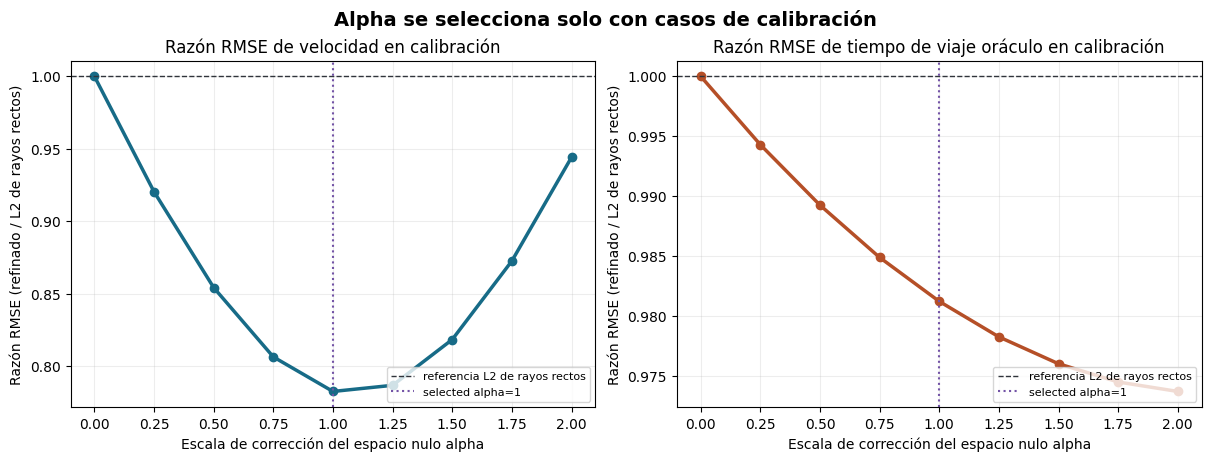

In [3]:
# Celda de análisis reproducible.
selection = analysis["calibration_selection"]
grid = selection['grid']
alpha = np.array(sorted(float(x) for x in grid))
velocity = np.array([grid[str(x)]["velocity_ratio"] for x in alpha])
time = np.array([grid[str(x)]["oracle_time_ratio"] for x in alpha])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for axis, values, title, color in (
    (ax[0], velocity, "Razón RMSE de velocidad en calibración", "#176b87"),
    (ax[1], time, "Razón RMSE de tiempo de viaje oráculo en calibración", "#b54f27"),
):
    axis.plot(alpha, values, "o-", lw=2.5, color=color)
    axis.axhline(1, color="#30343b", lw=1, ls="--", label="referencia L2 de rayos rectos")
    axis.axvline(
        selection["selected_alpha"],
        color="#7353a6",
        lw=1.5,
        ls=":",
        label=f"selected alpha={selection['selected_alpha']:g}",
    )
    axis.set(xlabel="Escala de corrección del espacio nulo alpha", ylabel="Razón RMSE (refinado / L2 de rayos rectos)", title=title)
    axis.grid(alpha=0.22)
    axis.legend(loc="lower right", frameon=True, fontsize=8)
fig.suptitle("Alpha se selecciona solo con casos de calibración", fontsize=14, fontweight="bold")


### El alpha seleccionado se determina en la grilla de calibración, donde las razones de velocidad y de tiempo oráculo deben cumplir la regla declarada. La línea vertical marca esa selección; los resultados retenidos no se usan para ajustarla. Una razón menor que uno significa mejora frente a esta referencia L2 de rayos rectos para esta métrica y partición, no una garantía de mejora en cada realización.

In [4]:
# Limite la selección de alpha a calibración; las cohortes retenidas solo miden sus consecuencias.
plt.show()
print(
    "Regla de selección:",
    selection["calibration_supported"],
    "— ambas métricas deben mejorar; luego se minimiza la razón media.",
)


Regla de selección: True — ambas métricas deben mejorar; luego se minimiza la razón media.


### Experimento 3 — Inspeccionar resultados pareados por caso

Edita `cohort_to_inspect` para examinar otra cohorte fija. Cada punto es una realización sintética pareada. Los valores menores que uno indican mejora frente al solución L2 de rayos rectos para esa métrica.

Los valores graficados se recalculan desde las entradas del notebook y usan las unidades indicadas en los ejes. La comparación muestra solo la métrica y partición declaradas; no establece un subsuelo único, precisión fuera de este proceso generador ni idoneidad operativa. Léala junto al control negativo retenido y las limitaciones anteriores.

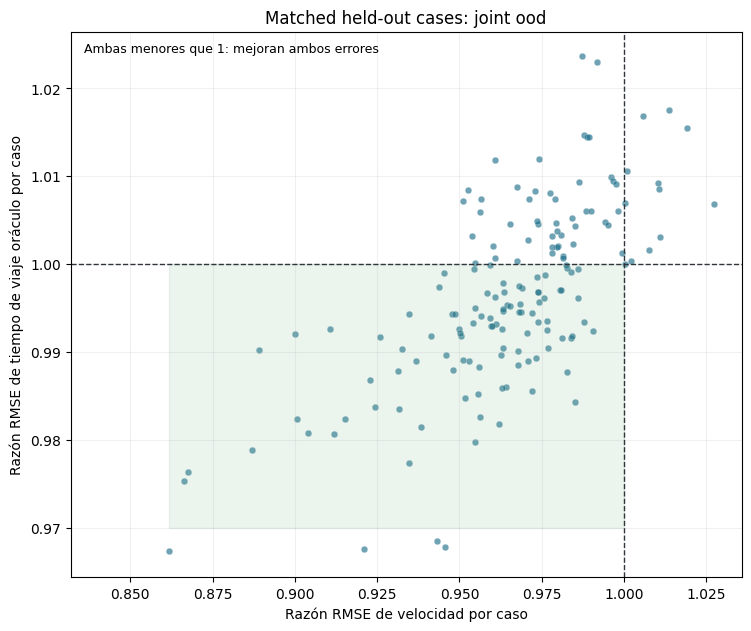

Razones medianas: velocity=0.9683 oracle-time=0.9962
Casos donde mejoran ambas: 100 de 160


In [5]:
# Celda de análisis reproducible.
cohort_to_inspect = "joint_ood"  # Change to id_test, family_only or acquisition_only and rerun this cell.
row = analysis["cohorts"][cohort_to_inspect]
x = np.asarray(row["velocity"]["case_ratios"], float)
y = np.asarray(row["oracle_time"]["case_ratios"], float)
fig, ax = plt.subplots(figsize=(7.4, 6.2), constrained_layout=True)
ax.scatter(x, y, s=23, alpha=0.62, c="#176b87", edgecolors="white", linewidths=0.25)
ax.axvline(1, color="#30343b", lw=1, ls="--")
ax.axhline(1, color="#30343b", lw=1, ls="--")
ax.fill_between(
    [max(0.5, float(x.min())), 1], [max(0.97, float(y.min()))] * 2, [1, 1], color="#64a77b", alpha=0.12
)
ax.set(
    xlabel="Razón RMSE de velocidad por caso",
    ylabel="Razón RMSE de tiempo de viaje oráculo por caso",
    title=f"Matched held-out cases: {cohort_to_inspect.replace('_',' ')}",
)
ax.grid(alpha=0.18)
ax.set_xlim(left=max(0.5, float(x.min()) - 0.03))
ax.set_ylim(bottom=min(0.97, float(y.min()) - 0.003))
ax.text(0.02, 0.98, "Ambas menores que 1: mejoran ambos errores", transform=ax.transAxes, va="top", fontsize=9)
plt.show()
print("Razones medianas:", f"velocity={np.median(x):.4f}", f"oracle-time={np.median(y):.4f}")
print("Casos donde mejoran ambas:", int(np.sum((x < 1) & (y < 1))), "de", len(x))


### Cada punto es una realización retenida pareada de la cohorte seleccionada. Las coordenadas menores que uno indican que el modelo refinado tiene menor error que su resultado L2 de rayos rectos emparejado; el conteo por cuadrante aporta más información que la media por sí sola. Estas muestras comparten un generador sintético y no constituyen evidencia independiente entre geologías o sistemas de adquisición.

In [6]:
# Limite la selección de alpha a calibración; las cohortes retenidas solo miden sus consecuencias.
print("Son razones por realización dentro de un generador sintético, no incertidumbre entre geologías.")


Son razones por realización dentro de un generador sintético, no incertidumbre entre geologías.


Los valores graficados se recalculan desde las entradas del notebook y usan las unidades indicadas en los ejes. La comparación muestra solo la métrica y partición declaradas; no establece un subsuelo único, precisión fuera de este proceso generador ni idoneidad operativa. Léala junto al control negativo retenido y las limitaciones anteriores.

### Cálculo por cohorte

Este cálculo agrupa resultados verificados por familia de casos declarada. Los conteos conservan ejecuciones fallidas y no convergentes; no establecen elegibilidad de campo ni recuperación del optimizador.


In [7]:
# Vuelva a ejecutar el análisis del recibo del producto e inspeccione los resúmenes completos de cohortes retenidas.
analysis_repeat = analyze_receipt(receipt)
for cohort_name, cohort_values in analysis_repeat["cohorts"].items():
    print(
        cohort_name,
        "n",
        cohort_values["count"],
        "mejoran ambas",
        cohort_values["both_metrics_better_fraction"],
        "razón de velocidad",
        cohort_values["velocity"]["aggregate_ratio"],
    )


id_test n 160 mejoran ambas 0.85 razón de velocidad 0.803488502997178
family_only n 80 mejoran ambas 0.7 razón de velocidad 0.9717635360245294
acquisition_only n 80 mejoran ambas 0.7375 razón de velocidad 0.8023377559195833
joint_ood n 160 mejoran ambas 0.625 razón de velocidad 0.9700567151783237


### Salida calculada del método

Calcula un estadístico de familia o cohorte pareada desde entradas verificadas; no ejecuta ni reajusta la inversión.


In [8]:
# Recalcule los efectos pareados para cada cohorte retenida.
for name, cohort in analysis["cohorts"].items():
    print(name, cohort["both_metrics_better_fraction"], cohort["count"])


id_test 0.85 160
family_only 0.7 80
acquisition_only 0.7375 80
joint_ood 0.625 160


### Salida calculada del método

Calcula un estadístico de familia o cohorte pareada desde entradas verificadas; no ejecuta ni reajusta la inversión.


In [9]:
# Inspeccione la selección de calibración sin seleccionar a partir de resultados de prueba.
selection = analysis["calibration_selection"]
print("alpha seleccionado", selection["selected_alpha"], "tamaño de la grilla", len(selection['grid']))


alpha seleccionado 1.0 tamaño de la grilla 9


### Salida calculada del método

Calcula un estadístico de familia o cohorte pareada desde entradas verificadas; no ejecuta ni reajusta la inversión.


In [10]:
# Cuente los casos donde mejoran ambas métricas en la cohorte seleccionada.
selected_cohort = analysis["cohorts"][cohort_to_inspect]
ratio_v = np.asarray(selected_cohort["velocity"]["case_ratios"])
ratio_t = np.asarray(selected_cohort["oracle_time"]["case_ratios"])
both_count = int(np.sum((ratio_v < 1) & (ratio_t < 1)))
print("mejoran ambas", both_count, "de", len(ratio_v))


mejoran ambas 100 de 160


### Construir el control acotado de adquisición

Reconstruya doce casos de la familia conjunta OOD con los operadores exactos de rayos rectos. Esta cohorte pequeña ejercita el proyector de producción sobre mallas físicas de velocidad y tiempos ruidosos; es un control algorítmico, no una nueva estimación retenida.


In [11]:
# Construya el control sintético acotado y obtenga sus operadores físicos de rayos.
import velocity_validation as velocity_physics
import velocity_nullspace_refinement_v11 as nullspace_method

ray_operators = velocity_physics.operators()
control_cohort = nullspace_method.make_cohort("joint_ood", ray_operators, fixture=True)
classical_control = velocity_physics.classical_predict(
    control_cohort, ray_operators, analysis["calibration_selection"]["selected_lambda"]
)
print("casos de control", len(control_cohort["records"]), "malla", control_cohort["velocity"].shape[1:])


casos de control 12 malla (16, 16)


### Calcular el espacio nulo de la adquisición

La base se obtiene de la matriz de longitudes de celda del diseño C; no se infiere del recibo agregado. El residuo informa si cada vector de la base es numéricamente invisible para esa adquisición linealizada de rayos rectos.


In [12]:
# Calcule la base ortonormal del espacio nulo de esta matriz de adquisición.
null_basis, null_basis_check = nullspace_method.nullspace_basis(ray_operators["C"]["cell"])
print("rango de rayos", null_basis_check["rank"], "nulidad", null_basis_check["nullity"])
print("residual máximo A N", null_basis_check["max_abs_A_times_basis"])


rango de rayos 127 nulidad 129
residual máximo A N 1.1503796922140982e-13


### Proyectar una corrección controlada

Una perturbación suave de velocidad del dos por ciento define una corrección candidata transparente para estudiar la proyección, sin fingir que existe un checkpoint entrenado. El método del repositorio lleva la diferencia de lentitud al espacio nulo de la adquisición y devuelve diagnósticos por geometría.


In [13]:
# Aplique el proyector de corrección de producción al candidato suave declarado.
space = np.linspace(-1.0, 1.0, velocity_physics.GRID)
pattern = np.broadcast_to(space[None, None, :], control_cohort["velocity"].shape)
controlled_prediction = classical_control * (1.0 + 0.02 * pattern)
projected_velocity, projection_check = nullspace_method.project_correction(
    control_cohort,
    classical_control,
    controlled_prediction,
    ray_operators,
    alpha=1.0,
    bases={"C": (null_basis, null_basis_check)},
)
print("forma proyectada", projected_velocity.shape)
print("residual proyectado", projection_check["C"]["max_abs_A_projected_correction"])


forma proyectada (12, 16, 16)
residual proyectado 1.328147661294743e-18


### Puntuar los modelos proyectados con el operador directo

La API calcula RMSE de velocidad y residuo de tiempos de viaje oráculo frente a las mismas observaciones generadas. La candidata es controlada, no aprendida; estas cifras validan únicamente el comportamiento de la proyección y no se mezclan con las afirmaciones retenidas del recibo.


In [14]:
# Evalúe las consecuencias en el modelo y los tiempos de viaje sobre la misma cohorte controlada.
control_score = velocity_physics.score(
    control_cohort,
    projected_velocity,
    classical_control,
    ray_operators,
    float("inf"),
)
print("razón de velocidad controlada", control_score["learned_to_classical_velocity_ratio"])
print("razón de tiempo oráculo controlado", control_score["learned_to_classical_oracle_ratio"])


razón de velocidad controlada 1.0216409467372431
razón de tiempo oráculo controlado 1.0029545512705966
